# Optimal control course project

Authors: 
1. Jonathan Somer, 307923383
2. Ofek Cohen, 214828063



# Setting:

## Background

We assume a tumor grows according to:
$$\dot{C} = C\cdot g(B)$$

This form implies the number of cells changes due to cell division or death. It is a generalization of a number of commonly used models of tumor growth (exponential, logistic, Gompertz, etc.). 

$B$ is some variable that we influence through a control $u$ (e.g., drug dosage). The function $g(B)$ defines how tumor growth rate (or shrinkage, for $g(B)<0$) depends on $B$. 

Many targeted systems exhibit "tolerance". Namely, the effect of a drug diminishes when it is administered continuously. 

To model this phenomenon, we adopt the framework of robust adaptation. A system exhibits robust adaptation if changing its parameters does not change its steady state.

For example, consider the following integral feedback system:
$$\dot{A} = a(\mu - B)$$
$$\dot{B} = b_1uA - b_2B$$

$B_{st} = \mu$ regardless of the values of $a$, $b_1$, and $b_2$.

If we assume that $g(B_{st}) > 0$, then a constant treatment will eventually lead to tumor growth.


## An insight that simplifies the problem

Instead of working with a 3D state space consisting of $(A,B,C)$, we can reduce the problem to a 2D state space consisting of $(A,B)$, while constructing an objective that is equivalent to minimizing the tumor size at time $T$.

We noticed that:

$$\frac{\frac{d}{dt}C}{C} = \frac{d}{dt}\log(C) = g(B)$$

Hence, 

$$\log(C(T)/C(0)) = \int_0^{T} g(B) dt$$


So the integral of $g(B)$ determines the fold-change in in tumor size. We'll directly minimize this integral.


## Optimal control problem:


$$\min_{A,B,u} \int_0^{T} g(B) dt$$

subject to:

$$\dot{A} = a(\mu - B)$$
$$\dot{B} = b_1uA - b_2B$$
$$A(0) = \frac{b_2\mu}{b_1}, \quad B(0) = \mu$$

$$ u \in [u_{\min}, u_{\max}] $$


## Applying Pontryagin's Maximum Principle to this problem


The Hamiltonian is:

$$H(x,u,\lambda) = g(B) + \lambda_1a(\mu-B) + \lambda_2(b_1uA - b_2B)$$

The optimal control minimizes the Hamiltonian at each time $t$:

$$u^* = \arg\min_u H(x^*,u,\lambda) = \arg\min_u \lambda_2b_1uA$$

We get bang-bang control:

$$\lambda_2b_1A <0 \Rightarrow u=u_{\max}$$
$$\lambda_2b_1A >0 \Rightarrow u=u_{\min}$$


The costate equations are:

$$\dot{\lambda}_1 = -\frac{\partial H}{\partial A} = -\lambda_2b_1u$$
$$\dot{\lambda}_2 = -\frac{\partial H}{\partial B} = -g'(B) + \lambda_1a + \lambda_2b_2$$

We do not have a terminal cost so we get:
$$\lambda(T) = 0$$

## Numerical solution

We are interested in nonlinear forms of $g(B)$. For example, B may be a nutrient that reduces tumor growth when it is scarce, but has no effect when it is abundant. For such functions we do not get a closed form solution, and we must solve the problem numerically.

We adopted the Forward-Backward Sweep Method, as described in the book Optimal Control Applied to Biological Models, by Suzanne Lenhart and John T. Workman.

We describe the approach below in comments along with our code.

# Objectives of this project

In our paper, we described 2 adaptive strategies capable of overcoming adaptation ("tolerance"). 

The first is resonant therapy, which aligns treatment with a natural oscillation in the $A,B$ system, gradually increasing the amplitude of oscillation of the targeted variable ($B$) until the tumor is eradicated.

The second strategy is called "reset therapy" where we pause treatment for a period of time, allowing the system to return to its steady state, and then resume treatment. The reset period sensitizes the system to treatment, allowing it to be effective again. Success of this approach relies on a timescale difference between the dynamics of the $A,B$ system and the tumor growth dynamics. Namely, the $A,B$ system must be fast relative to tumor growth.

The primary objective of the current project is to explore under which conditions each of these strategies is optimal, and whether PMP uncovers strategies we did not think of.

We consider the effect of three components:

1. The form and parameters of the $g(B)$ function
2. The parameters of the A,B system
3. The time horizon $T$



## Forms of the g(B) function 


### First form: one-sided linear

The first form we consider reflects the idea that $B$ is a nutrient that reduces tumor growth when it is scarce, but has no effect when it is abundant.

$$g_1(B) = c_1 - c_2(\mu -B)^+$$

Case 1: $B < \mu$:
$$g_1(B) = c_1-c_2(\mu-B)$$
$$g_1'(B) = c_2$$


Case 2: $B >\mu$:
$$g_1(B) = c_1$$
$$g_1'(B) = 0$$

### Second form: linear

This form reflects the idea that $B$ is factor that reduces tumor growth when it is scarce, and increases tumor growth when it is abundant.

$$g_2(B) = c_1 - c_2(\mu -B)$$
$$g_2'(B) = c_2$$


### Third form: quadratic

This form suits factors that tuned to a specific level, and are harmful when they are scarce or abundant.

$$g_3(B) = c_1 - c_2(\mu -B)^2$$
$$g_3'(B) = 2c_2(\mu - B)$$


## Dimensional analysis
 
The model has eight parameters ($a, b_1, b_2, \mu, c_1, c_2, u_{\min}, u_{\max}$) plus the horizon $T$. Rescaling states and time collapses these to a few dimensionless groups. We map out the different regimes of this model and infer the corresponding optimal policies.
 
### Units


Recall the model is:
$$\dot{A} = a(\mu - B)$$
$$\dot{B} = b_1uA - b_2B$$
$$\dot{C} = C\cdot (c_1 - c_2f(\mu - B))$$

Where $f(x) =  x^+$, $x$, or $x^2$.  

| Parameter | Units                                                                      |
| --------- | -------------------------------------------------------------------------- |
| $b_2$     | $1/\text{time}$                                                            |
| $b_1$     | $[B]\,/\,([A]\cdot\text{time})$                                            |
| $a$       | $[A]\,/\,([B]\cdot\text{time})$                                            |
| $\mu$     | $[B]$                                                                      |
| $c_1$     | $1/\text{time}$                                                            |
| $c_2$     | $1/(\text{time}\cdot[B]^k)$, with $k=1$ for $g_1, g_2$ and $k=2$ for $g_3$ |

$u$ is dimensionless, $u_{\max} = 1$ defines the off-treatment, and $u_{\min}$ is the inhibition of $b_1$ under the maximal tolerable dose.

### Rescaling the states
 
Scale $B,A$ by their steady state values (at $u=1$).
 
$$\tilde{B} := \frac{B}{\mu}, \qquad \tilde{A} := \frac{A}{b_2\mu/b_1}$$
 
Then
 
$$\dot{\tilde{A}} = \frac{b_1}{b_2\mu}\,a(\mu - \mu\tilde{B}) = \frac{a b_1}{b_2}\,(1-\tilde{B})$$
 
$$\dot{\tilde{B}} = \frac{1}{\mu}\left[b_1 u \tilde{A}\,\frac{b_2\mu}{b_1} - b_2\mu\tilde{B}\right] = b_2\,(u\tilde{A} - \tilde{B})$$
 
### Rescaling time
 
To get a single parameter, we rescale time:
$$\tau := b_2 t$$
Then
$$t=\frac{1}{b_2}\tau, \qquad \frac{d}{d\tau}A = \frac{1}{b_2}\frac{d}{dt}A$$
Writing $'$ for $d/d\tau$:
 
$$\tilde{A}' = q\,(1-\tilde{B})$$
$$\tilde{B}' = u\tilde{A} - \tilde{B}$$
$$\tilde{A}(0) = 1, \quad \tilde{B}(0) = 1$$
 
with a single dimensionless parameter
 
$$q = \frac{a\,b_1}{b_2^2}$$
So, the $A,B$ system has one parameter $q$. It is directly related to the damping of the system. You can see this by computing eigenvalues of the linearized system (or "projecting" the system onto a 1-dimensional equation for $B$, which maps to a mass on a spring system):

Linearize the system around $A=1, B=1$ (assume $u=u_{\max}=1$)
$$ J = \begin{bmatrix} 0 & -q \\ u & -1 \end{bmatrix} = \begin{bmatrix} 0 & -q \\ 1 & -1 \end{bmatrix} $$
The characteristic polynomial is:

$$P(\lambda) = -\lambda \cdot (-1-\lambda) - (-q) = \lambda^2 + \lambda + q$$
The eigenvalues are:

$$\lambda_{1,2} = \frac{-1 \pm \sqrt{1 - 4q}}{2}$$
When $q > 1/4$ we get complex eigenvalues, the system "oscillates" and there is an overshoot as the system adapts to therapy. When $q<1/4$ the system is damped, 

The relaxation time is determined by the slowest eigenvalue, i.e $\frac{1}{\min |\text{Real}(\lambda)|}$. For the underdamped case ($q > 1/4$), both eigenvalues have $|\text{Real}(\lambda)| = \frac{1}{2}$ . So the relaxation time is $2$. For the real case ($q < 1/4$), the smaller eigenvalue satisfies:

$$\min |\text{Real}(\lambda(q))| = |\frac{-1+\sqrt{1-4q}}{2}|=\frac{1-\sqrt{1-4q}}{2}$$
We want to compare systems with different damping that relax on a similar timescale. So we rescale time again according to the relaxation time of the $A,B$ system. Namely, we rescale by 
$$\tau_r(q)=\frac{1}{\min |\text{Real}(\lambda(q))|}$$

So: 
$$\hat{t}=\frac{\tau}{\tau_r(q)}$$

We get:
$$\frac{d}{d\hat{t}}A=\tau_r(q)q(1-B)$$
$$\frac{d}{d\hat{t}}B=\tau_r(q)(uA-B)$$
### Rescaling the growth function
 
All three forms share the structure $g(B) = c_1 - c_2\, f(\mu - B)$, with $f(x) = x^+$, $x$, or $x^2$. 

Plug in $\tilde{B}$,  $f(\mu - \mu\tilde{B}) = \mu^k f(1-\tilde{B})$, depending on the exponent.

We move $\mu^k$ into $c_2$:

$$\tilde{c}_2 := c_2\,\mu^k$$
That is, $\tilde{c}_2 = c_2\mu$ for $g_1, g_2$ and $\tilde{c}_2 = c_2\mu^2$ for $g_3$. 
$$g(B) = c_1 - \tilde{c}_2\, f(1-\tilde{B})$$
 Rescale the tumor growth function the same way to get $\hat{t}$  time units:
 $$\frac{d}{d\hat{t}}C=\frac{\tau_r(q)}{b_2}\cdot \frac{d}{dt}C=\frac{\tau_r(q)}{b_2} \cdot C \cdot (c_1 - \tilde{c_2}f(1-B))=C\cdot (\frac{\tau_r(q)c_1}{b_2}-\frac{\tau_r(q)\tilde{c_2}}{b_2}f(1-B))$$

Define two dimensionless parameters

$$\rho:=\frac{\tau_r(q)c_1}{b_2}$$
$$\rho\alpha:=\frac{\tau_r(q)\tilde{c_2}}{b_2}$$
So:
$$\alpha = \frac{b_2}{\tau_r(q)c_1}\cdot \frac{\tau_r(q)\tilde{c_2}}{b_2}=\frac{\tilde{c_2}}{c_1}$$
$$\frac{d}{d\hat{t}}C = C\cdot(\rho - \rho \alpha f(1-\tilde{B})) $$
$\rho$ is the tumor growth-rate when $B$ is at steady-state. $\alpha$ sets the strength of the drug. For example, if $\alpha=2$ then when $\tilde{B}=0$  we get a net tumor shrink rate of $\rho - 2\rho=-\rho$ 


Overall, we work with the new rescaled system (simplifying notation):

$$\dot{A} = \tau_r(q)q\,(1-B)$$
$$\dot{B} = \tau_r(q)(uA - B)$$
$$\dot{C} = C\cdot(\rho - \alpha \rho f(1-B)) $$
$$A(0) = 1, \quad B(0) = 1$$

The dimensionless optimal control objective becomes
$$\min_{u}  \int_0^{T} g\,dt = \int_0^{T} \rho - \rho\alpha f(1-B)dt = \rho T - \rho\alpha \int_0^{T}f(1-B)dt$$
We notice that the optimal control doesn't depend on $\rho, \alpha$. If we fix the time horizon $T$, then $\rho,\alpha$ determine the objective value, i.e. the tumor fold-change, but the same $u(t)$ is optimal for all constants. In fact we can compute the optimal $\int_0^{T}f(1-B)dt$  once and then map out tumor fold-change reduction efficiently for all combinations of $\rho$ and $\alpha$. We'll optimize the simplified objective:

$$\min_u \int_0^Tg(B)dt=\min_u\int_0^T-f(1-B)dt$$

We therefore structure our analysis as follows:

For each form of $f$, we consider a number of values of $q$ corresponding with damped and non-damped systems: $q=0.01, 0.1, 1,10,100$ (see plots below)

For each combination we'll plot:
1. Trajectories of $u,A,B,C,\lambda_1, \lambda_2$
2. 2D heatmap of the tumor fold-change as a function of $\alpha$ and $\rho$

And we'll plot a heatmap with the optimal strategy for different combinations of $T,q$.

## PMP over the dimensionless system

Overall, we work with the new rescaled system (simplifying notation):

$$\min_{u}  \int_0^{T} -f(1-B)dt $$

Subject to:
$$\dot{A} = \tau_r(q)q\,(1-B)$$
$$\dot{B} = \tau_r(q)(uA - B)$$
$$A(0) = 1, \quad B(0) = 1$$
  
The hamiltonian is:

$$H(x,u,\lambda) = -f(1-B) + \lambda_1\tau_r(q)q(1-B) + \lambda_2\tau_r(q)(uA-B)$$

The optimal control satisfies:
$$H(x^*,u^*,\lambda) = \min_u H(x^*,u,
\lambda)$$
So:
$$\lambda_2\tau_r(q)Au^* = \min_u \lambda_2\tau_r(q) Au $$
We get the same bang-bang control law:
$$\lambda_2A < 0 \Rightarrow u^* = u_{\max}$$
$$\lambda_2A > 0 \Rightarrow u^* = u_{\min}$$
The adjoint equations:

$$\dot{\lambda}_1 = -\frac{\partial}{\partial{A}}H = -\lambda_2\tau_r(q)u$$
$$\dot{\lambda}_2 = -\frac{\partial}{\partial{B}}H = -\left[(-f(1-B))'(B) -\lambda_1\tau_r(q)q - \lambda_2\tau_r(q)\right] = f(1-B)' + \lambda_1\tau_r(q)q + \lambda_2\tau_r(q)$$
And $\lambda(T)=0$


We need the derivatives $f(1-B)'$ of the different $f$:

### First form: one-sided linear $f_1(x) = x^+$

Case 1: $B < 1$: $f_1(1-B)=1-B \Rightarrow f_1(1-B)'=-1$ 
Case 2: $B >1$:$f_1(1-B)=0 \Rightarrow f_1(1-B)'=0$ 

### Second form: linear $f_2(x) = x$

 $f_2(1-B)=1-B \Rightarrow f_2(1-B)'=-1$  

### Third form: quadratic $f_3(x) = x^2$

$f_3(1-B)=(1-B)^2 \Rightarrow f_3(1-B)'=-2(1-B)$  



# Analysis:

In [1]:
from scipy.integrate import solve_ivp
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
rho = 0.1
alpha = 100
umin = 0.5
umax = 1

q_low = 0.1
q_high = 10

A0 = 1
B0 = 1
C0 = 1
x0 = [A0, B0, C0]

lambda_1_T = 0
lambda_2_T = 0
lambda_0 = [lambda_1_T, lambda_2_T]

## Growth function $g(B)$

In [3]:
class GrowthFunction:
    def __init__(self, rho, alpha) -> None:
        self.rho = rho
        self.alpha = alpha

    def __call__(self, B) -> float:
        return self.rho - self.rho*self.alpha * self.f(1-B)

    def f(self, B) -> float:
        raise NotImplementedError

    def df(self, B) -> float:
        raise NotImplementedError

    def dg(self, B) -> float:
        raise NotImplementedError

    def __str__(self) -> str:
        raise NotImplementedError

    def _repr_latex_(self) -> str:
        return str(self)

class g1(GrowthFunction):

    def f(self, x):
        return max(x, 0)

    def df(self, B):
        """Derivative of (1-B)^+ by B"""
        if B < 1:
            return -1
        else:
            return 0

    def dg(self, B) -> float:
        if B < 1:
            return self.rho * self.alpha
        else:
            return 0

    def __str__(self) -> str:
        return "$g_1(B)$ - asymmetric linear"

class g2(GrowthFunction):

    def f(self, x):
        return x

    def df(self, B):
        """Derivative of (1-B) by B"""
        return -1

    def dg(self, B) -> float:
        return self.rho * self.alpha

    def __str__(self) -> str:
        return "$g_2(B)$ - linear"

class g3(GrowthFunction):

    def f(self, x):
        return x**2

    def df(self, B):
        """Derivative of (1-B)^2 by B"""
        return -2*(1-B)

    def dg(self, B) -> float:
        return 2*self.rho * self.alpha*(1 - B)

    def __str__(self) -> str:
        return "$g_3(B)$ - quadratic"

In [4]:
class GrowthFunction:
    def __init__(self, rho, alpha) -> None:
        self.rho = rho
        self.alpha = alpha

    def __call__(self, B):
        return self.rho - self.rho * self.alpha * self.f(1.0 - B)

    def f(self, x):
        raise NotImplementedError

    def df(self, B):
        raise NotImplementedError

    def dg(self, B):
        raise NotImplementedError

    def _repr_latex_(self) -> str:
        return str(self)


class g1(GrowthFunction):
    def f(self, x):
        return np.maximum(x, 0.0)

    def df(self, B):
        """Derivative of (1-B)^+ by B"""
        return np.where(B < 1.0, -1.0, 0.0)

    def dg(self, B):
        return np.where(B < 1.0, self.rho * self.alpha, 0.0)

    def __str__(self) -> str:
        return "$g_1(B)$ - asymmetric linear"


class g2(GrowthFunction):
    def f(self, x):
        return x

    def df(self, B):
        """Derivative of (1-B) by B"""
        return np.full_like(B, -1.0, dtype=float)

    def dg(self, B):
        return np.full_like(B, self.rho * self.alpha, dtype=float)

    def __str__(self) -> str:
        return "$g_2(B)$ - linear"


class g3(GrowthFunction):
    def f(self, x):
        return x**2

    def df(self, B):
        """Derivative of (1-B)^2 by B"""
        return -2.0 * (1.0 - B)

    def dg(self, B):
        return 2.0 * self.rho * self.alpha * (1.0 - B)

    def __str__(self) -> str:
        return "$g_3(B)$ - quadratic"

In [5]:
for g_class in [g1,g2,g3]:
    
    g = g_class(rho=rho, alpha=alpha)

    display(g)

    # high B should leave us with the basic growth rate rho
    print('f(1): ', g.f(1))
    print('g(1): ', g(1))
    assert abs(g(1)-  rho) < 1e-3, print(g(2))


    print('g(0): ', g(0))


f(1):  1.0
g(1):  0.1
g(0):  -9.9


f(1):  1
g(1):  0.1
g(0):  -9.9


f(1):  1
g(1):  0.1
g(0):  -9.9


In [6]:
from scipy.optimize import OptimizeResult as OdeResult
from scipy.integrate import cumulative_trapezoid

def const_u(t: float) -> float | np.ndarray:
    return np.ones_like(t) * umin

def t_relax(q):
    if q > 1/4:
        return 2
    else:
        return 2/(1-np.sqrt(1-4*q))

def f_state(t,x,q,u_func):
    A,B = x
    u = u_func(t)
    tr = t_relax(q)

    dA = tr*q*(1 - B)
    dB = tr*(u*A - B)

    return dA, dB

def solve_C(B_grid,t_grid,g):
    g_grid = np.array([g(b) for b in B_grid])
    logCs = cumulative_trapezoid(g_grid, t_grid, initial=0)
    return logCs


def f_costate(t,x,q,g,u_func,B_func):
    u = u_func(t)
    B = B_func(t)
    tr = t_relax(q)

    df = g.df(B)
    
    l1, l2 = x

    dl1 = -l2*tr*u
    dl2 = df + l1*tr * q + l2*tr

    return dl1, dl2


def get_interp_func(t_grid, x_grid):
    return lambda t: np.interp([t], t_grid, x_grid)[0]


def forward_backward_optimal_solution(tmin, tmax, t_grid_n, q, g, max_iterations=200):

    # 1. guess initial u:
    t_grid = np.linspace(tmin, tmax, t_grid_n)
    # u0_grid = np.repeat(umin, t_grid_n)
    u0_grid = np.random.uniform(low=umin, high=umax, size=t_grid_n)
    u_grid_prev = u0_grid

    # Use Radau for stiff small-q regime,RK45/LSODA for moderate/large q
    ode_method = 'Radau' if q < 0.1 else 'RK45'
        

    for _ in range(max_iterations):

        u_func = get_interp_func(t_grid, u_grid_prev)

        # 2. solve x forward in time:
        state_sol = solve_ivp(lambda t, x: f_state(t, x, q=q, u_func=u_func),
                              t_span=[tmin, tmax], y0=[A0, B0], t_eval=t_grid, 
                              method=ode_method, rtol=1e-7, atol=1e-9)
        A_grid = state_sol.y[0,:]
        B_grid = state_sol.y[1,:]
        B_func = get_interp_func(t_grid, B_grid)

        # 3. solve costate trajectory backwards in time:
        costate_sol = solve_ivp(lambda t, x: 
                    f_costate(t, x, q=q, g=g, u_func=u_func, B_func=B_func), 
                    t_span=[tmax, tmin], y0=lambda_0, t_eval=t_grid[::-1], 
                    method=ode_method, rtol=1e-7, atol=1e-9)

        # 4. update u:
        l2_grid = costate_sol.y[1,::-1] # reverse time again, so it aligns with the state
        u_grid = np.where(l2_grid * A_grid < -1e-12, umax, umin)

        if np.allclose(u_grid_prev, u_grid):
            print('converged!')
            break

        r = 0.1
        u_grid_prev = r*u_grid + (1-r)*u_grid_prev


    # compute C once based on B:
    logC_grid = solve_C(B_grid, t_grid, g)

    # concatenate the state and co-state solutions:
    assert np.allclose(costate_sol.t[::-1], state_sol.t)
    costate_y = costate_sol.y[:, ::-1]

    sol = OdeResult(
        t=state_sol.t,
        y=np.vstack([state_sol.y, logC_grid, costate_y]),  # rows: A, B, C, lambda_1, lambda_2
        # u=np.array([u_func(t) for t in state_sol.t]),
        # u=u_grid,
        # u=u_grid_prev,
        u = np.where(u_grid_prev > (umax + umin)/2, umax, umin)
    )
    assert sol.y.shape == (5, len(t_grid))


    return sol


def get_constant_solution(tmin,tmax,t_grid,q,g,):
    AB_solution = solve_ivp(lambda t, x: f_state(t=t, x=x, q=q, u_func=const_u), t_span=[tmin, tmax], y0=[A0,B0], t_eval=t_grid)
    logC_grid = solve_C(B_grid=AB_solution.y[1,:], t_grid=t_grid, g=g)
    AB_solution.y = y=np.vstack([AB_solution.y, logC_grid])
    return AB_solution


# Visualizing different q:

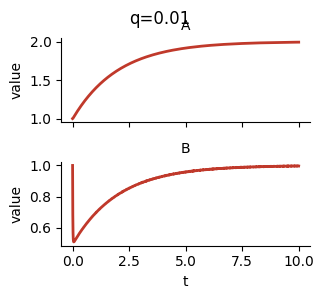

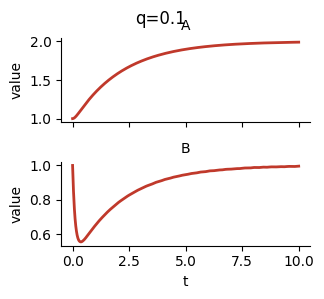

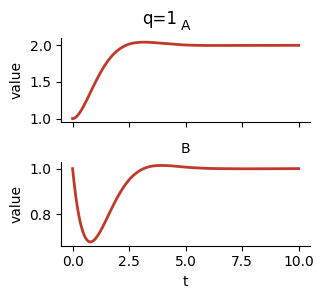

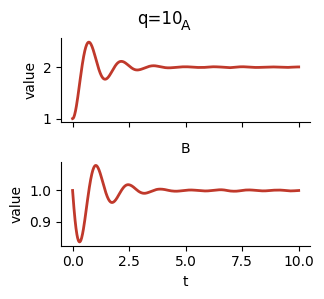

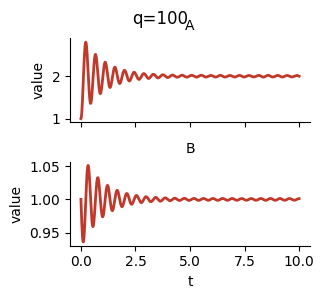

In [7]:
def plot_step_response(tmin, tmax, q, g):

    t_grid = np.linspace(tmin, tmax, 1000)

    state_sol = solve_ivp(lambda t, x: f_state(t=t, x=x, q=q, u_func=const_u), t_span=[tmin, tmax], y0=[A0, B0], t_eval=t_grid)

    sol_df = (
        pd.DataFrame(state_sol.y.T[:,:2], columns=['A', 'B'])
        .assign(t=state_sol.t)
        .melt(id_vars='t', var_name='variable', value_name='value')
    )

    g = sns.relplot(
        data=sol_df, x='t', y='value', row='variable', color='#C0392B', lw=2,
        kind='line', facet_kws={'sharey': False}, legend=False, height=1.5, aspect=2.2
    )
    g.set_titles('{row_name}')

    g.fig.suptitle(f'q={q}')


def relaxation_time(q, u):
    qu = q*u
    if qu < 1/4: # overdamped
        return 1/qu
    else: # underdamped
        return 2

for q in [1/100, 1/10, 1, 10, 100]:
    tmax = 10
    plot_step_response(tmin=0, tmax=tmax, q=q, g=g1(rho=rho, alpha=alpha))

In [ ]:

def plot_solution(sol, constant_sol, title):
    t = sol.t
    As = sol.y[0,:]
    Bs = sol.y[1,:]
    Cs = sol.y[2,:]
    lambda_1s = sol.y[3,:]
    lambda_2s = sol.y[4,:]
    us = sol.u

    As_constant = constant_sol.y[0,:]
    Bs_constant = constant_sol.y[1,:]
    Cs_constant = constant_sol.y[2,:]
    us_constant = np.apply_along_axis(arr=t, func1d=const_u, axis=0)

    fig, axs = plt.subplots(nrows=6, ncols=1, figsize=(6,6), sharex=True)

    # some style:
    lw = 2
    optimal_color =   '#C0392B'
    constant_color =  '#A6A6A6'


    ax = axs[0]
    sns.lineplot(x=t, y=As, ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    sns.lineplot(x=t, y=As_constant, ax=ax, label='constant therapy', lw=lw, color=constant_color)
    ax.set_ylabel('$A$')
    ax.text(t[-1] + 0.02, As[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, As_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)

    ax = axs[1]
    sns.lineplot(x=t, y=Bs, ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    sns.lineplot(x=t, y=Bs_constant, ax=ax, label='constant therapy', lw=lw, color=constant_color)
    ax.set_ylabel('$B$')
    ax.text(t[-1] + 0.02, Bs[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, Bs_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)

    ax = axs[2]
    sns.lineplot(x=t, y=Cs, ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    sns.lineplot(x=t, y=Cs_constant, ax=ax, label='constant therapy', lw=lw, color=constant_color)
    ax.set_ylabel('$\\log C(t) / C(0)$')
    ax.text(t[-1] + 0.02, Cs[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, Cs_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)
    # sns.lineplot(x=t, y=np.log2(1 + Cs), ax=ax, label='optimal therapy', lw=lw, color=optimal_color)
    # sns.lineplot(x=t, y=np.log2(1 + Cs_constant), ax=ax, label='constant therapy', lw=lw, color=constant_color)
    # ax.set_ylabel('$\\log 1 + C$')
    # ax.text(t[-1] + 0.02, np.log2(1+Cs[-1]), 'optimal', color=optimal_color, va='center', fontsize=8)
    # ax.text(t[-1] + 0.02, np.log2(1+Cs_constant[-1]), 'constant', color=constant_color, va='center', fontsize=8)

    ax = axs[3]
    sns.lineplot(x=t, y=lambda_1s, ax=ax, lw=lw, color=optimal_color)
    ax.set_ylabel('$\\lambda_1$')

    ax = axs[4]
    sns.lineplot(x=t, y=lambda_2s, ax=ax, lw=lw, color=optimal_color)
    ax.set_ylabel('$\\lambda_2$')

    ax = axs[5]
    sns.lineplot(x=t, y=us, ax=ax, color=optimal_color)
    sns.lineplot(x=t, y=us_constant, ax=ax, color=constant_color)
    ax.set_ylabel('u')
    ax.text(t[-1] + 0.02, us[-1], 'optimal', color=optimal_color, va='center', fontsize=8)
    ax.text(t[-1] + 0.02, us_constant[-1], 'constant', color=constant_color, va='center', fontsize=8)


    for ax in axs:
        sns.despine(ax=ax)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.grid(False)
    
    for ax in axs[0:3]:
        ax.legend().remove()

    fig.suptitle(title)
    plt.show()


from scipy.integrate import trapezoid
from matplotlib.colors import LinearSegmentedColormap


def plot_logfc_C_over_rho_alpha_grid(optimal_sol, g, title, show_threshold=False):
    t = optimal_sol.t
    tmax = max(t)
    B = optimal_sol.y[1,:]
    f = [g.f(1-_B) for _B in B]
    F = trapezoid(f, t)

    
    alphas = np.logspace(start=-3, stop=3, num=7, base=10)
    rhos = np.logspace(start=-3, stop=3, num=7, base=10)
    log_fcs = np.zeros((len(alphas),len(rhos)))

    for row, alpha in enumerate(alphas):
        for col, rho in enumerate(rhos):
            log_fcs[row, col] = rho*tmax - rho*alpha*F

    fig, ax = plt.subplots(figsize=(4,4))
    cmap = LinearSegmentedColormap.from_list('green_white', ["#28ca69", 'white'])
    sns.heatmap(log_fcs, ax=ax, cmap=cmap, vmin=-10, vmax=0,
                cbar_kws={'label': 'C log fold-change \n(truncated at 0)', 'extend': 'min'})
    ax.invert_yaxis()  # α increases upward
    ax.set_xlabel('ρ')
    ax.set_ylabel('α')

    ax.set_xticklabels([f'$10^{{{i}}}$' for i in np.arange(-3,4)])
    ax.set_yticklabels([f'$10^{{{i}}}$' for i in np.arange(-3,4)])

    fig.suptitle(title)
    return 

In [11]:
_rho = 1
_alpha = 2**3

for _g in [g1, g2, g3]:
    g = _g(rho=_rho, alpha=_alpha)
    display(g)
    for q in [0.01, 0.1, 1, 10, 100]:
        
        tmin = 0
        tmax = 10

        t_grid_n = 100*int(tmax)
        t_grid = np.linspace(tmin, tmax, t_grid_n)

        optimal_sol = forward_backward_optimal_solution(tmin, tmax, t_grid_n, q, g, max_iterations=100)
        constant_sol = get_constant_solution(tmin, tmax,t_grid,q,g)

        plot_solution(optimal_sol, constant_sol, title=f'{g}, q={q}')
        plot_logfc_C_over_rho_alpha_grid(optimal_sol, g, title=f'{g}, q={q}')


KeyboardInterrupt: 

# Interpretation of the results:

The first interesting observation is that the optimal strategy does not depend on parameters of the tumor growth function. These parameters only affect whether the optimal strategy is effective or not, i.e. whether the tumor shrinks or grows.

We were surprised that three strategies emerge from the PMP analysis (one of which we did not think of before)

For intermediate q, we see the "reset" strategy - alternate between treatment and no treatment, allowing the homeostatic system to reset, and resensitize for another treatment cycle. For high q we see the "resonant" strategy - amplitudes of B increase well over the maximal value achieved by a constant therapy. 


For very low q however we see something else. The optimal control "chatters" rapidly, keeping $A$ approximately constant at $A=\sqrt{2}\approx 1.4$. This was true across both $f(x) = x^+, x^2$.

We initially thought this was a numerical artifact, but we realized that it is actually a real phenomenon.

As $q\rightarrow 0$ the system essentially becomes one-dimensional, where $B$ approaches its quasi-steady state value:

Lets work with this system (before scaling time by the slow eigenvalue):
$$\dot{A} = q\,(1-B)$$
$$\dot{B} = uA - B$$
 At QSS:
 $$B_{\text{qss}}=uA$$
 
 $$\dot{A}=q(1-uA)$$
Consider the objective:

$$\min_{u} \int_0^T -f(1-uA)dt$$
s.t:
$$\dot{A}=q(1-uA)$$

We can compute the average time on the minimal and maximal control, such that $A$ doesn't change:
$$\langle \dot{A} \rangle = \alpha q(1-u_{\min}A) + (1-\alpha) q(1-u_{\max}A) = 0$$
$$\alpha (1-\frac{1}{2}A) + (1-\alpha) (1-A)=0$$
$$\alpha (1-\frac{1}{2}A) -\alpha (1-A) = -(1-A)$$
$$\alpha  = -\frac{(1-A)}{[(1-\frac{1}{2}A) - (1-A)]}=\frac{A-1}{\frac{1}{2}A}$$

So the fraction of time on treatment, which keeps $A$ constant is:

$$\alpha(A)  = \frac{A-1}{\frac{1}{2}A}$$

Now we want to find the optimal constant $A$ for maximizing tumor shrinkage rate. What is the shrinkage rate for on and off-treatment? From the derivative of $\dot{A}\propto 1-uA$, and the initial condition $A(0)=1$, then $A \in (1,2)$ To see this, consider $u_{\min}$. we get $\dot{A} = 1-\frac{1}{2}A$ and the derivative is positive for any $A\in(1,2)$ until $A$ reaches 2, where the derivative is $0$ (a stable fixed point). For $u_{\max}$ we get $\dot{A}=1-A$ and for any $A\in (1,2)$ the derivative is negative until $A$ reaches 1 (another stable fixed point). 

When $u=u_{\min}$ we get $uA = \frac{1}{2}A < 1$ for $A\in (1,2)$ and for $u=u_{\max}$ we get $uA = A > 1$ for $A\in (1,2)$ 

Therefore the average tumor shrinkage rate is:
$$\alpha f(1-\frac{1}{2}A) + (1-\alpha)f(1-A) = \alpha f(1-\frac{1}{2}A)=\frac{(A-1)(1-\frac{1}{2}A)}{\frac{1}{2}A}$$
We can find the optimal value of $A$ by taking the derivative:

$$\frac{d}{dA}\frac{(A-1)(1-\frac{1}{2}A)}{\frac{1}{2}A}=...=\frac{2}{A^2}-1 = 0$$
And we get $A=\sqrt{2}$, pretty cool!